# Day 088 | Soil Classification from CPT using CNN

**Author:** Ripon Chandra Malo

## Capstone Project: 1D CNN for Soil Behavior Type from CPT Profiles

Cone Penetration Testing (CPT) produces continuous depth profiles of tip resistance (qc), sleeve friction (fs), and pore pressure (u2). The Robertson Soil Behavior Type (SBT) chart classifies soil based on normalized CPT parameters, but manual interpretation is time-consuming.

In this project, we train a 1D Convolutional Neural Network to automatically classify soil behavior type from short sliding windows of CPT depth profiles.

**Objectives:**
- Generate synthetic CPT depth series with known soil layers
- Create sliding window samples for 1D CNN input
- Build and train a 1D CNN classifier
- Evaluate accuracy and visualize predictions along depth

In [1]:
# ───── Part 1: Imports and Setup ─────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
print('All libraries loaded successfully.')

All libraries loaded successfully.


## Part 2: Synthetic CPT Data Generation

We simulate multiple CPT soundings through layered soil profiles. Each sounding consists of continuous measurements at 2 cm depth intervals. Soil Behavior Types (SBT) follow the Robertson classification:

| SBT Zone | Soil Type | Typical qc (MPa) | Typical Rf (%) |
|----------|-----------|-------------------|----------------|
| 2 | Organic / Peat | 0.5-1.5 | 3-8 |
| 3 | Clay | 1-4 | 2-5 |
| 4 | Silt Mixture | 2-8 | 1-3 |
| 5 | Sand Mixture | 5-15 | 0.5-2 |
| 6 | Sand | 10-30 | 0.3-1 |

In [2]:
# ───── Part 2: Generate Synthetic CPT Profiles ─────
def generate_cpt_sounding(max_depth=20.0, dz=0.02, sounding_id=0):
    """Generate a single synthetic CPT sounding with layered soils."""
    depths = np.arange(0, max_depth, dz)
    n_points = len(depths)

    # Define random layer boundaries
    n_layers = np.random.randint(4, 8)
    boundaries = np.sort(np.random.uniform(1.0, max_depth - 1.0, n_layers - 1))
    boundaries = np.concatenate([[0], boundaries, [max_depth]])

    # SBT classes: 0=Organic, 1=Clay, 2=Silt, 3=Sand Mix, 4=Sand
    sbt_params = {
        0: {'qc_mean': 1.0, 'qc_std': 0.3, 'rf_mean': 5.0, 'rf_std': 1.5, 'u2_factor': 0.8},
        1: {'qc_mean': 2.5, 'qc_std': 0.8, 'rf_mean': 3.5, 'rf_std': 1.0, 'u2_factor': 1.2},
        2: {'qc_mean': 5.0, 'qc_std': 1.5, 'rf_mean': 2.0, 'rf_std': 0.5, 'u2_factor': 0.5},
        3: {'qc_mean': 10.0, 'qc_std': 3.0, 'rf_mean': 1.0, 'rf_std': 0.3, 'u2_factor': 0.2},
        4: {'qc_mean': 20.0, 'qc_std': 5.0, 'rf_mean': 0.5, 'rf_std': 0.2, 'u2_factor': 0.0}
    }

    qc = np.zeros(n_points)
    fs = np.zeros(n_points)
    u2 = np.zeros(n_points)
    sbt = np.zeros(n_points, dtype=int)

    for i in range(n_layers):
        layer_type = np.random.choice([0, 1, 2, 3, 4], p=[0.10, 0.25, 0.20, 0.25, 0.20])
        params = sbt_params[layer_type]

        mask = (depths >= boundaries[i]) & (depths < boundaries[i + 1])
        n_layer = mask.sum()
        if n_layer == 0:
            continue

        # Add depth-dependent increase and noise
        depth_factor = 1 + 0.02 * depths[mask]
        qc[mask] = (params['qc_mean'] * depth_factor +
                    np.random.normal(0, params['qc_std'], n_layer))
        rf = params['rf_mean'] + np.random.normal(0, params['rf_std'], n_layer)
        rf = np.clip(rf, 0.1, 10)
        fs[mask] = qc[mask] * rf / 100
        u2[mask] = (depths[mask] * 9.81 * params['u2_factor'] +
                    np.random.normal(0, 5, n_layer))
        sbt[mask] = layer_type

    qc = np.clip(qc, 0.1, 50)
    fs = np.clip(fs, 0.001, 2.0)
    u2 = np.clip(u2, 0, 300)

    return pd.DataFrame({
        'sounding_id': sounding_id,
        'depth_m': depths,
        'qc_MPa': qc,
        'fs_MPa': fs,
        'u2_kPa': u2,
        'sbt_class': sbt
    })

# Generate multiple soundings
n_soundings = 20
all_data = [generate_cpt_sounding(sounding_id=i) for i in range(n_soundings)]
df = pd.concat(all_data, ignore_index=True)

print(f'Total data points: {len(df)}')
print(f'Number of soundings: {n_soundings}')
print(f'\nSBT class distribution:')
sbt_names = {0: 'Organic', 1: 'Clay', 2: 'Silt Mix', 3: 'Sand Mix', 4: 'Sand'}
for cls, name in sbt_names.items():
    count = (df['sbt_class'] == cls).sum()
    print(f'  {name}: {count} ({100*count/len(df):.1f}%)')
df.head()

Total data points: 20000
Number of soundings: 20

SBT class distribution:
  Organic: 1204 (6.0%)
  Clay: 5729 (28.6%)
  Silt Mix: 3745 (18.7%)
  Sand Mix: 6279 (31.4%)
  Sand: 3043 (15.2%)


,sounding_id,depth_m,qc_MPa,fs_MPa,u2_kPa,sbt_class
0,0,0.00,0.396711,0.025089,2.068564,0
1,0,0.02,0.852559,0.036882,6.867403,0
2,0,0.04,1.118574,0.062953,0.000000,0
3,0,0.06,0.722445,0.028231,0.000000,0
4,0,0.08,1.025550,0.023559,3.596551,0


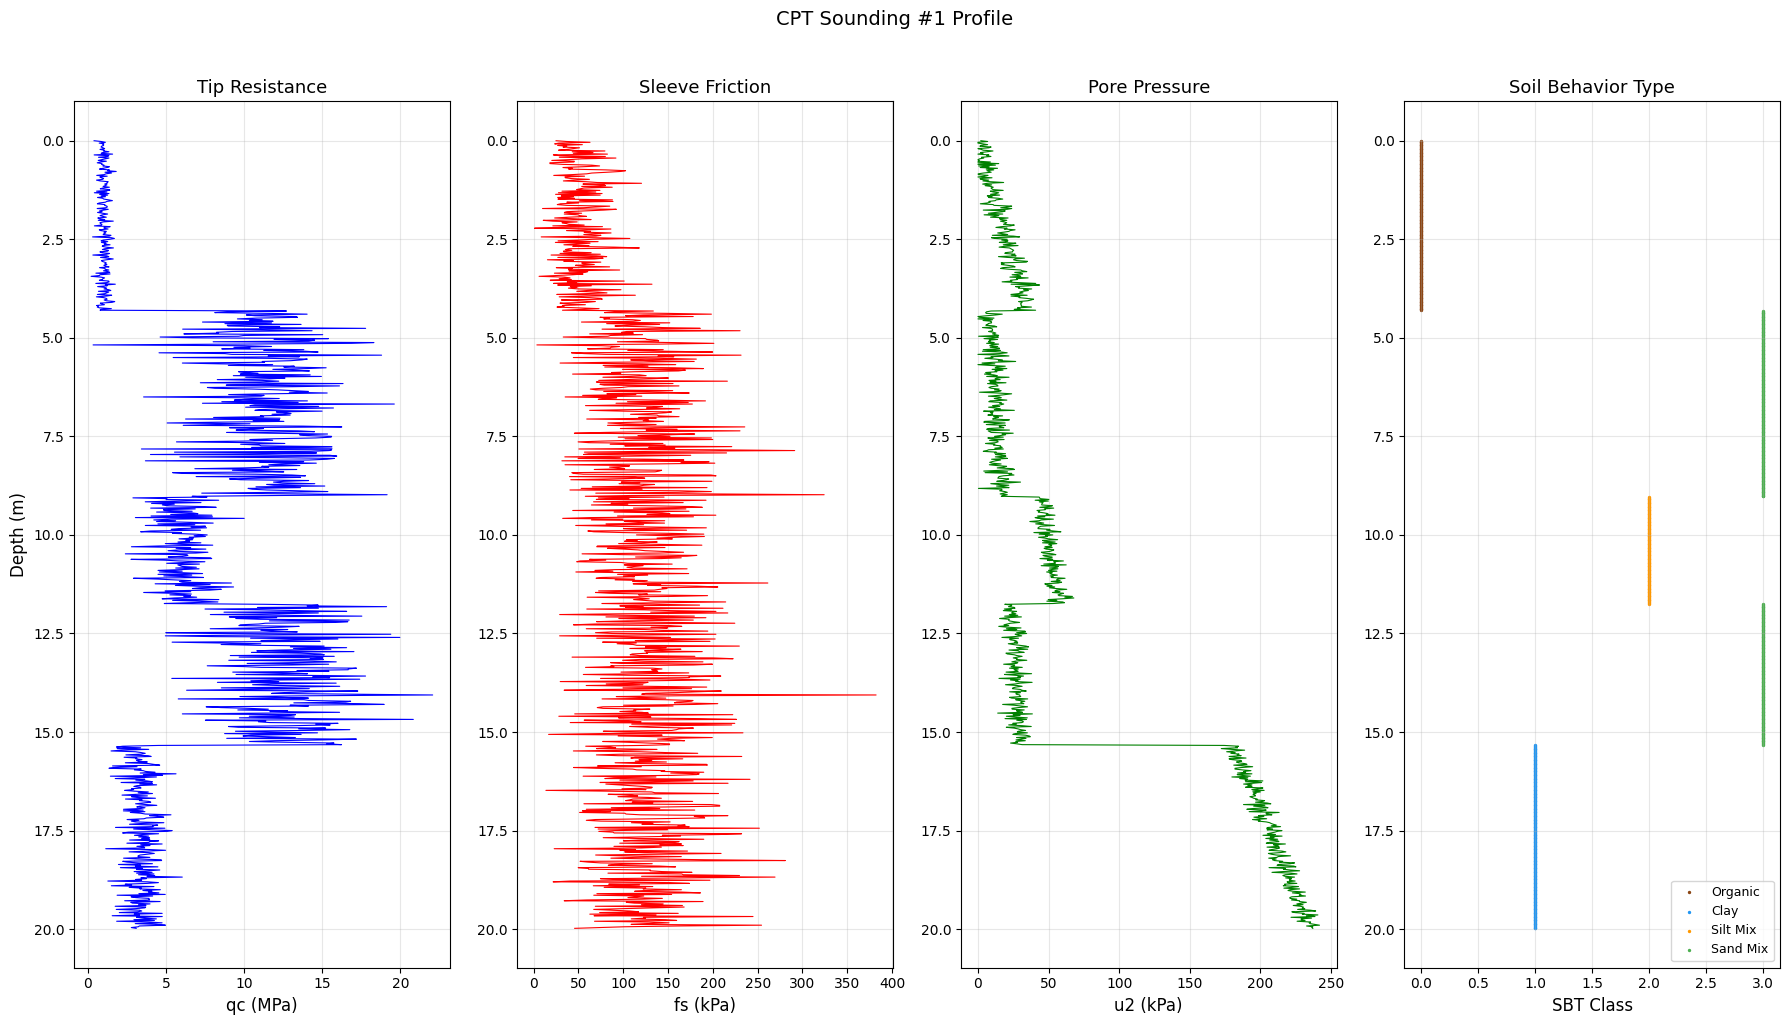

In [3]:
# ───── Part 3: Visualize Sample CPT Profiles ─────
fig, axes = plt.subplots(1, 4, figsize=(18, 10))

# Plot first sounding
s0 = df[df['sounding_id'] == 0]

axes[0].plot(s0['qc_MPa'], s0['depth_m'], 'b-', linewidth=0.8)
axes[0].set_xlabel('qc (MPa)', fontsize=12)
axes[0].set_ylabel('Depth (m)', fontsize=12)
axes[0].set_title('Tip Resistance', fontsize=13)
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3)

axes[1].plot(s0['fs_MPa'] * 1000, s0['depth_m'], 'r-', linewidth=0.8)  # convert to kPa
axes[1].set_xlabel('fs (kPa)', fontsize=12)
axes[1].set_title('Sleeve Friction', fontsize=13)
axes[1].invert_yaxis()
axes[1].grid(True, alpha=0.3)

axes[2].plot(s0['u2_kPa'], s0['depth_m'], 'g-', linewidth=0.8)
axes[2].set_xlabel('u2 (kPa)', fontsize=12)
axes[2].set_title('Pore Pressure', fontsize=13)
axes[2].invert_yaxis()
axes[2].grid(True, alpha=0.3)

# SBT profile
colors_sbt = ['#8B4513', '#2196F3', '#FF9800', '#4CAF50', '#FFC107']
for cls, name in sbt_names.items():
    mask = s0['sbt_class'] == cls
    if mask.any():
        axes[3].scatter(np.ones(mask.sum()) * cls, s0.loc[mask, 'depth_m'],
                       c=colors_sbt[cls], s=2, label=name)
axes[3].set_xlabel('SBT Class', fontsize=12)
axes[3].set_title('Soil Behavior Type', fontsize=13)
axes[3].invert_yaxis()
axes[3].legend(loc='lower right', fontsize=9)
axes[3].grid(True, alpha=0.3)

plt.suptitle('CPT Sounding #1 Profile', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('cpt_profile.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# ───── Part 4: Create Sliding Window Samples ─────
window_size = 25  # 25 readings = 50 cm window at 2 cm intervals
n_features = 3    # qc, fs, u2

def create_windows(data, window_size):
    """Create sliding window samples from CPT data."""
    X_windows = []
    y_windows = []

    for sid in data['sounding_id'].unique():
        sounding = data[data['sounding_id'] == sid]
        values = sounding[['qc_MPa', 'fs_MPa', 'u2_kPa']].values
        labels = sounding['sbt_class'].values

        for i in range(len(values) - window_size + 1):
            window = values[i:i + window_size]
            # Label is the most frequent class in the window center
            center = i + window_size // 2
            label = labels[center]
            X_windows.append(window)
            y_windows.append(label)

    return np.array(X_windows), np.array(y_windows)

X, y = create_windows(df, window_size)
print(f'Window samples shape: {X.shape}')  # (n_samples, window_size, n_features)
print(f'Labels shape: {y.shape}')
print(f'\nClass distribution in windows:')
for cls, name in sbt_names.items():
    count = (y == cls).sum()
    print(f'  {name}: {count} ({100*count/len(y):.1f}%)')

Window samples shape: (19520, 25, 3)
Labels shape: (19520,)

Class distribution in windows:
  Organic: 1144 (5.9%)
  Clay: 5633 (28.9%)
  Silt Mix: 3649 (18.7%)
  Sand Mix: 6147 (31.5%)
  Sand: 2947 (15.1%)


In [5]:
# ───── Part 5: Data Preparation ─────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Normalize features per channel
scalers = []
X_train_sc = np.zeros_like(X_train, dtype=np.float32)
X_test_sc = np.zeros_like(X_test, dtype=np.float32)

for ch in range(n_features):
    scaler = StandardScaler()
    X_train_sc[:, :, ch] = scaler.fit_transform(X_train[:, :, ch])
    X_test_sc[:, :, ch] = scaler.transform(X_test[:, :, ch])
    scalers.append(scaler)

# Reshape for 1D CNN: (batch, channels, length)
X_train_t = torch.FloatTensor(X_train_sc).permute(0, 2, 1)  # (N, 3, 25)
X_test_t = torch.FloatTensor(X_test_sc).permute(0, 2, 1)
y_train_t = torch.LongTensor(y_train)
y_test_t = torch.LongTensor(y_test)

print(f'Training: {X_train_t.shape}')
print(f'Test:     {X_test_t.shape}')

Training: torch.Size([15616, 3, 25])
Test:     torch.Size([3904, 3, 25])


## Part 6: 1D CNN Architecture

The 1D CNN processes CPT depth windows with:
- 3 input channels (qc, fs, u2)
- Three convolutional blocks with increasing filters
- Max pooling and batch normalization
- Global average pooling before the classifier head

In [6]:
# ───── Part 6: Define 1D CNN ─────
class CPT_CNN(nn.Module):
    def __init__(self, n_channels, n_classes, window_size):
        super(CPT_CNN, self).__init__()

        self.conv_blocks = nn.Sequential(
            # Block 1
            nn.Conv1d(n_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            # Block 2
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            # Block 3
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)  # Global average pooling
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        x = self.conv_blocks(x)
        x = self.classifier(x)
        return x

n_classes = len(sbt_names)
model = CPT_CNN(n_channels=n_features, n_classes=n_classes, window_size=window_size)
print(model)
print(f'\nTotal parameters: {sum(p.numel() for p in model.parameters())}')

CPT_CNN(
  (conv_blocks): Sequential(
    (0): Conv1d(3, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_f

In [7]:
# ───── Part 7: Train CNN ─────
# Class weights
class_counts = np.bincount(y_train, minlength=n_classes)
class_weights = 1.0 / np.maximum(class_counts, 1)
class_weights = class_weights / class_weights.sum() * n_classes
weights_tensor = torch.FloatTensor(class_weights)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.5)

epochs = 40
train_losses, val_losses, val_accs = [], [], []

for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    train_losses.append(epoch_loss / len(train_loader))

    model.eval()
    with torch.no_grad():
        val_out = model(X_test_t)
        val_loss = criterion(val_out, y_test_t).item()
        val_losses.append(val_loss)
        _, preds = torch.max(val_out, 1)
        acc = (preds == y_test_t).float().mean().item()
        val_accs.append(acc)

    scheduler.step()

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}] - Loss: {train_losses[-1]:.4f}, '
              f'Val Loss: {val_loss:.4f}, Val Acc: {acc:.3f}')

print(f'\nBest validation accuracy: {max(val_accs):.3f}')

Epoch [10/40] - Loss: 0.0139, Val Loss: 0.0120, Val Acc: 0.995


Epoch [20/40] - Loss: 0.0079, Val Loss: 0.0125, Val Acc: 0.992


Epoch [30/40] - Loss: 0.0049, Val Loss: 0.0093, Val Acc: 0.995


Epoch [40/40] - Loss: 0.0028, Val Loss: 0.0127, Val Acc: 0.994

Best validation accuracy: 0.997


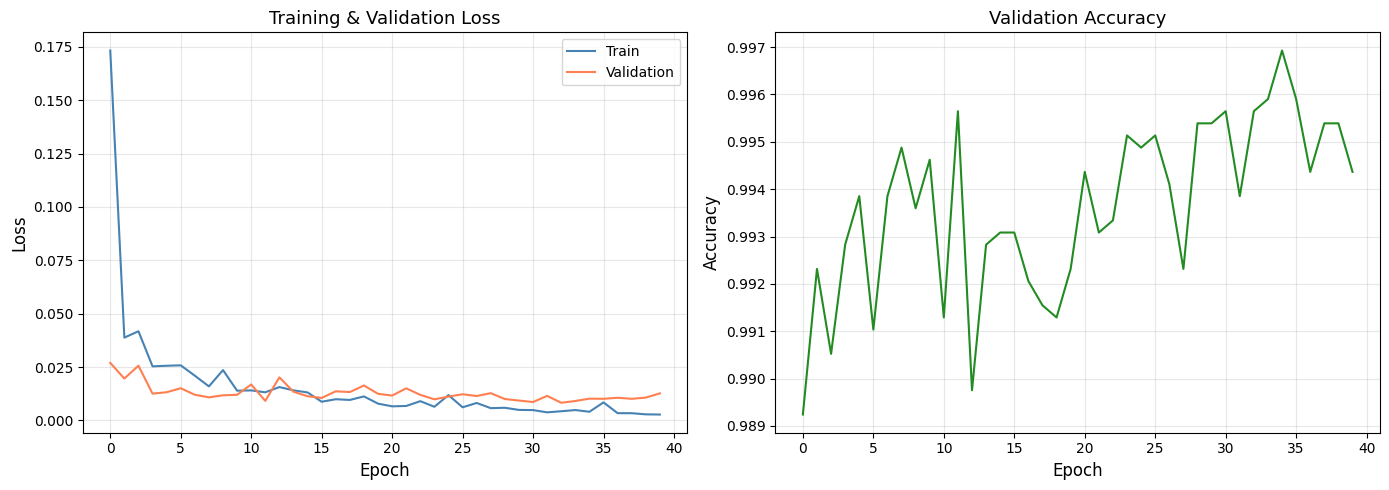

In [8]:
# ───── Part 8: Training History ─────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, label='Train', color='steelblue', linewidth=1.5)
ax1.plot(val_losses, label='Validation', color='coral', linewidth=1.5)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Training & Validation Loss', fontsize=13)
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(val_accs, color='forestgreen', linewidth=1.5)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Accuracy', fontsize=12)
ax2.set_title('Validation Accuracy', fontsize=13)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('cnn_training.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# ───── Part 9: Evaluation ─────
model.eval()
with torch.no_grad():
    outputs = model(X_test_t)
    _, y_pred = torch.max(outputs, 1)
    y_pred = y_pred.numpy()

target_names = [sbt_names[i] for i in range(n_classes)]
print('=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=target_names))
print(f'Overall Accuracy: {accuracy_score(y_test, y_pred):.3f}')

=== Classification Report ===
              precision    recall  f1-score   support

     Organic       0.99      1.00      0.99       229
        Clay       1.00      1.00      1.00      1127
    Silt Mix       0.99      1.00      0.99       730
    Sand Mix       1.00      0.99      0.99      1229
        Sand       0.99      1.00      0.99       589

    accuracy                           0.99      3904
   macro avg       0.99      1.00      0.99      3904
weighted avg       0.99      0.99      0.99      3904

Overall Accuracy: 0.994


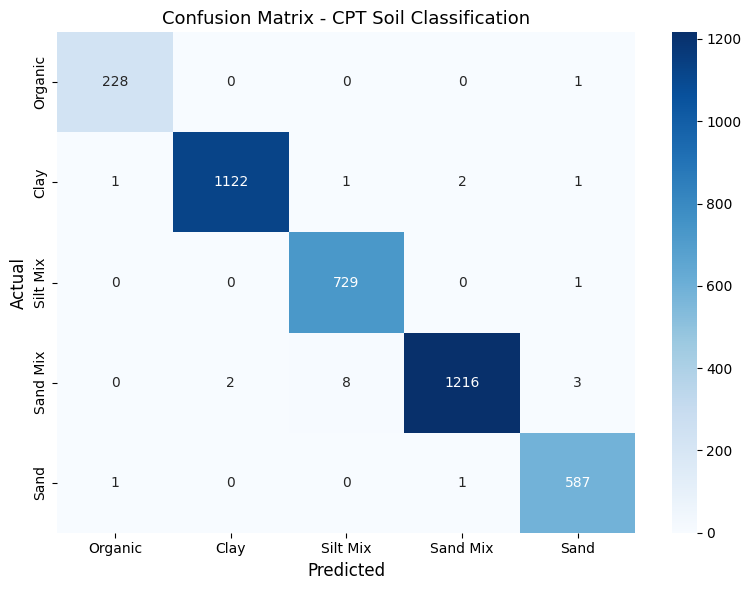

In [10]:
# ───── Part 10: Confusion Matrix ─────
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=target_names, yticklabels=target_names)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual', fontsize=12)
ax.set_title('Confusion Matrix - CPT Soil Classification', fontsize=13)
plt.tight_layout()
plt.savefig('confusion_matrix_cpt.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# ───── Part 11: Predict Full Sounding Profile ─────
# Predict SBT for an entire sounding
test_sounding_id = 0
sounding_data = df[df['sounding_id'] == test_sounding_id]
X_full, y_full = create_windows(
    sounding_data.reset_index(drop=True), window_size)

# Scale and predict
X_full_sc = np.zeros_like(X_full, dtype=np.float32)
for ch in range(n_features):
    X_full_sc[:, :, ch] = scalers[ch].transform(X_full[:, :, ch])

X_full_t = torch.FloatTensor(X_full_sc).permute(0, 2, 1)
model.eval()
with torch.no_grad():
    full_out = model(X_full_t)
    _, full_pred = torch.max(full_out, 1)
    full_pred = full_pred.numpy()

# Get depths for center of each window
depths_center = sounding_data['depth_m'].values[window_size//2 : window_size//2 + len(full_pred)]

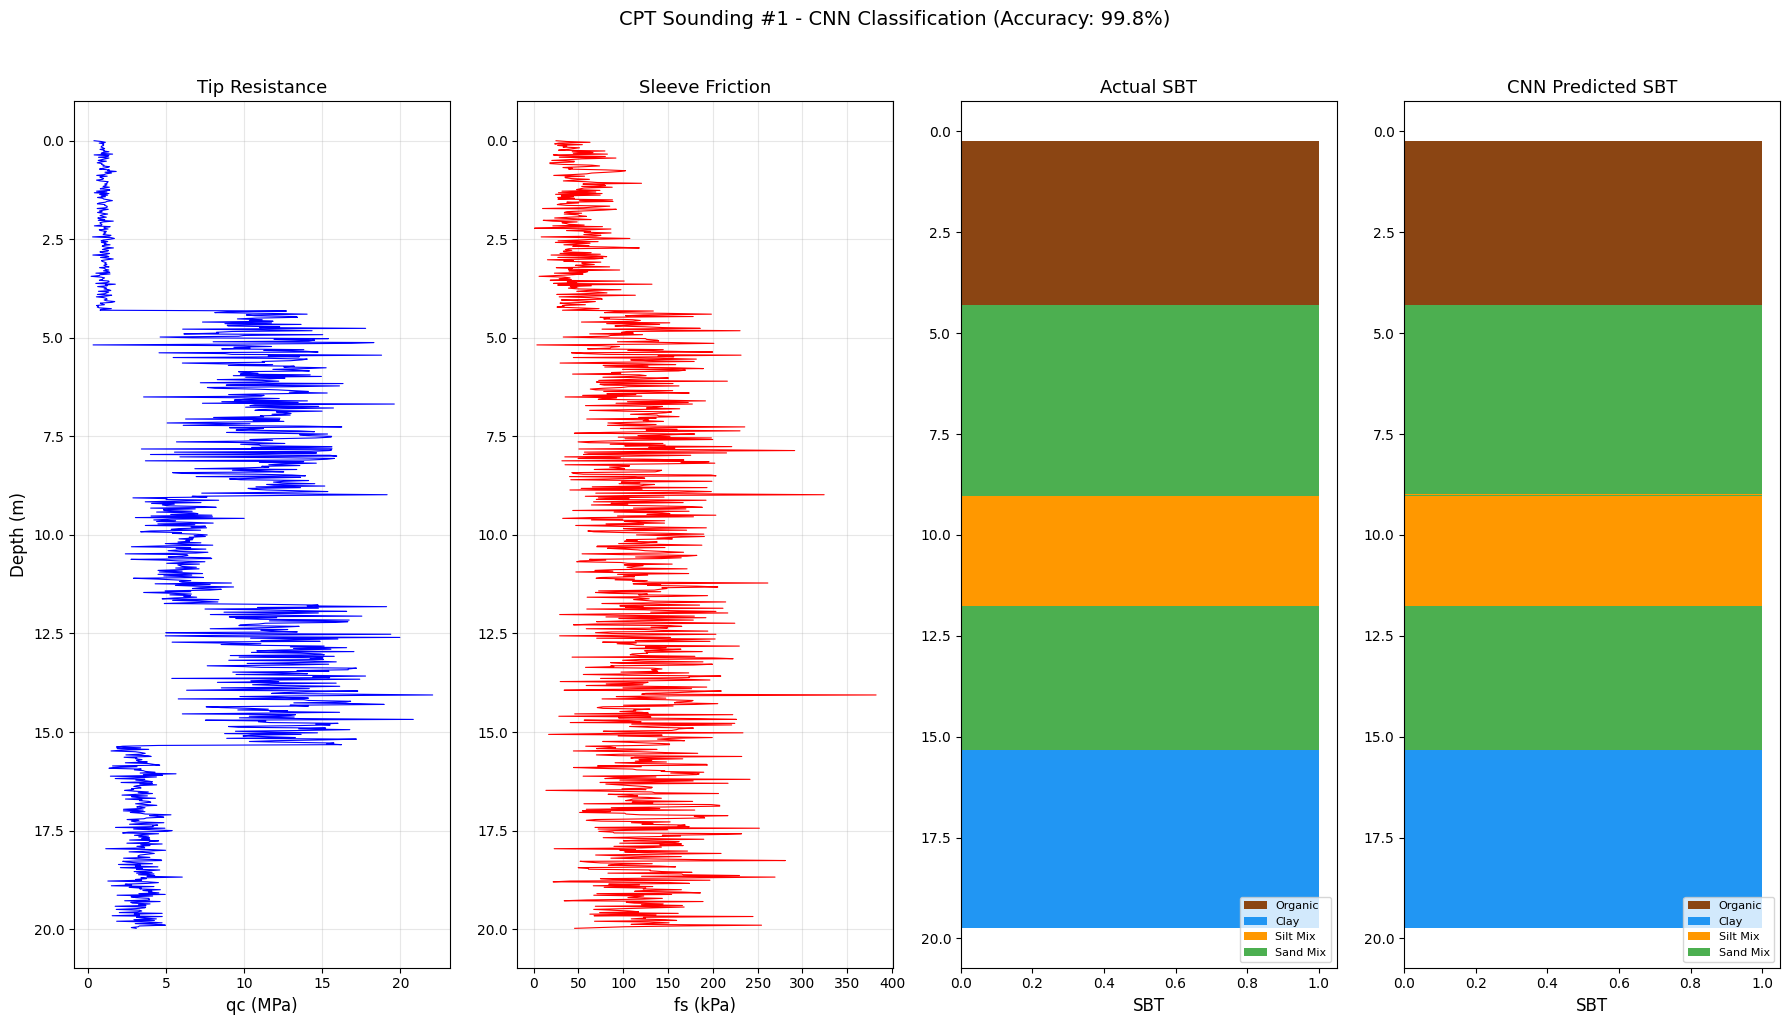

In [12]:
# ───── Part 12: Visualize Full Profile Prediction ─────
fig, axes = plt.subplots(1, 4, figsize=(18, 10))

axes[0].plot(sounding_data['qc_MPa'], sounding_data['depth_m'], 'b-', linewidth=0.8)
axes[0].set_xlabel('qc (MPa)', fontsize=12)
axes[0].set_ylabel('Depth (m)', fontsize=12)
axes[0].set_title('Tip Resistance', fontsize=13)
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3)

axes[1].plot(sounding_data['fs_MPa'] * 1000, sounding_data['depth_m'], 'r-', linewidth=0.8)
axes[1].set_xlabel('fs (kPa)', fontsize=12)
axes[1].set_title('Sleeve Friction', fontsize=13)
axes[1].invert_yaxis()
axes[1].grid(True, alpha=0.3)

# Actual SBT
for cls, name in sbt_names.items():
    mask = y_full == cls
    if mask.any():
        axes[2].barh(depths_center[mask], 1, height=0.02,
                     color=colors_sbt[cls], label=name)
axes[2].set_xlabel('SBT', fontsize=12)
axes[2].set_title('Actual SBT', fontsize=13)
axes[2].invert_yaxis()
axes[2].legend(loc='lower right', fontsize=8)

# Predicted SBT
for cls, name in sbt_names.items():
    mask = full_pred == cls
    if mask.any():
        axes[3].barh(depths_center[mask], 1, height=0.02,
                     color=colors_sbt[cls], label=name)
axes[3].set_xlabel('SBT', fontsize=12)
axes[3].set_title('CNN Predicted SBT', fontsize=13)
axes[3].invert_yaxis()
axes[3].legend(loc='lower right', fontsize=8)

accuracy_full = (full_pred == y_full).mean()
plt.suptitle(f'CPT Sounding #1 - CNN Classification (Accuracy: {accuracy_full:.1%})',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('profile_prediction.png', dpi=150, bbox_inches='tight')
plt.show()

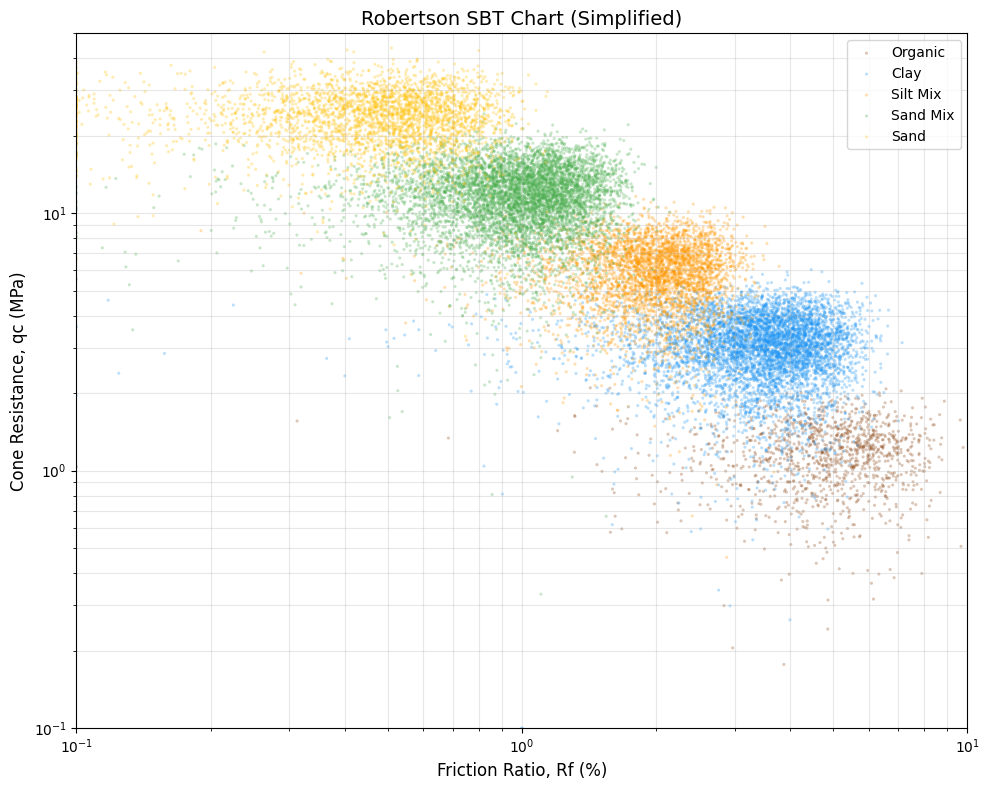

In [13]:
# ───── Part 13: Robertson SBT Chart Visualization ─────
# Compute normalized parameters for visualization
Rf = (df['fs_MPa'] / df['qc_MPa']) * 100  # Friction ratio (%)
Qt = df['qc_MPa']  # Simplified normalized tip resistance

fig, ax = plt.subplots(figsize=(10, 8))
for cls, name in sbt_names.items():
    mask = df['sbt_class'] == cls
    ax.scatter(Rf[mask], Qt[mask], c=colors_sbt[cls], label=name,
               alpha=0.3, s=5, edgecolors='none')

ax.set_xlabel('Friction Ratio, Rf (%)', fontsize=12)
ax.set_ylabel('Cone Resistance, qc (MPa)', fontsize=12)
ax.set_title('Robertson SBT Chart (Simplified)', fontsize=14)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.1, 10)
ax.set_ylim(0.1, 50)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.savefig('robertson_chart.png', dpi=150, bbox_inches='tight')
plt.show()

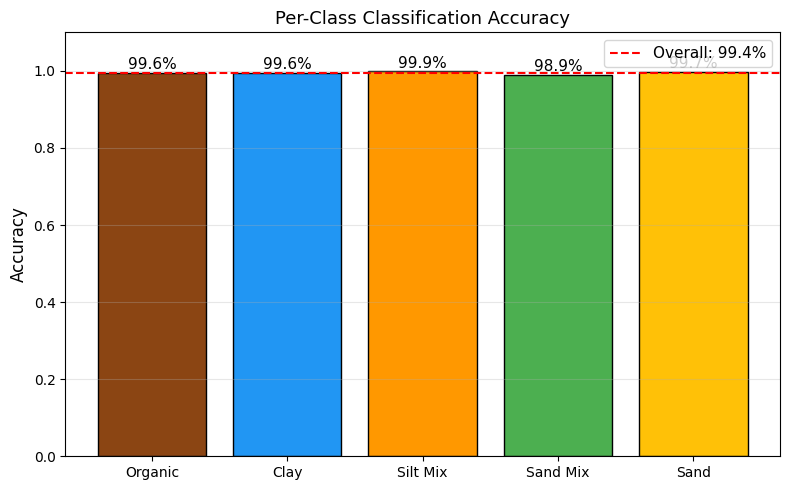

In [14]:
# ───── Part 14: Per-Class Accuracy Analysis ─────
fig, ax = plt.subplots(figsize=(8, 5))

per_class_acc = []
for cls in range(n_classes):
    mask = y_test == cls
    if mask.sum() > 0:
        acc = (y_pred[mask] == cls).mean()
    else:
        acc = 0
    per_class_acc.append(acc)

bars = ax.bar(target_names, per_class_acc, color=colors_sbt, edgecolor='black')
for bar, acc in zip(bars, per_class_acc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{acc:.1%}', ha='center', fontsize=11)

ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Per-Class Classification Accuracy', fontsize=13)
ax.set_ylim(0, 1.1)
ax.axhline(y=accuracy_score(y_test, y_pred), color='red', linestyle='--',
           label=f'Overall: {accuracy_score(y_test, y_pred):.1%}')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Takeaways

1. **1D CNNs effectively classify soil behavior type from CPT profiles** by learning depth-dependent patterns in qc, fs, and u2 measurements.

2. **Sliding window approach preserves spatial context** -- the CNN sees local trends rather than isolated point measurements, improving classification accuracy.

3. **Layer transitions are the most challenging zones** for classification, where mixed signals from adjacent soil types reduce accuracy at boundaries.

4. **Clean sands and organic soils are most distinct** in CPT signatures and achieve higher classification accuracy, while silt mixtures are harder to distinguish.

5. **Automated CPT interpretation dramatically speeds up site characterization** workflows, reducing subjective manual classification effort.

## Next Steps

- Apply to real CPT data from field investigations
- Add pore pressure ratio (Bq) as a fourth channel
- Test bidirectional LSTM for sequence-aware classification
- Incorporate transfer learning from pre-trained CPT models
- Extend to full Robertson 9-zone SBT classification